# Reservoir subsidence: Van Opstal and Tempone

One notebook for the mathematics of surface subsidence from a prescribed, valid dataset.
Run from top to bottom. Dependencies: NumPy, SciPy, pandas and Matplotlib. No package imports,
test suite or input-validation code.

The main example compares **Van Opstal (1974)** with the **surface specialization of
Tempone, Fjær & Landrø (2010)** in the layout of their Figure 3. Both curves are calculated,
not traced from the paper. The last section applies the same functions to the repository's
synthetic reservoir CSV. All displacements below are **positive downward**; distances are metres.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.polynomial.legendre import leggauss
from scipy.special import j0

plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.2})


## 1. Compaction and the Geertsma–Van Opstal kernel

For source cell $i$, define the positive depletion magnitude $p_d=p_{initial}-p_{final}$,
the compaction strength $D_i=A_i h_i C_{m,i}p_{d,i}$ [m³], and horizontal distance $r_i$.
Surface subsidence is $s(x,y)=\sum_i D_i G(r_i,c_i,k_i)$.
Here $c$ is source-centre depth and $k$ is basement depth from the same surface datum.

The Geertsma surface kernel is
$$G_G(r,c)=\frac{1-\nu}{\pi}\frac{c}{(r^2+c^2)^{3/2}}.$$
The Van Opstal image terms below retain the repository's original coefficients for
$\nu=0.25$: $(a_{11},a_{12},a_{21},a_{22},b_{11},b_{21})=(1,-0.778,2,2.8,-0.2,4)$.
The repeated $a$ terms are written as a two-term sum to keep the expression compact.


In [2]:
def geertsma(r, c, nu=0.25):
    return (1-nu)/np.pi * c/(np.asarray(r)**2+c**2)**1.5

def van_opstal(r, c, k, nu=0.25):
    r2 = np.asarray(r)**2
    q = 3-4*nu
    correction = np.zeros_like(r2, dtype=float)
    for a, image_depth in [(1.0, 2.0), (-0.778, 2.8)]:
        u, v = image_depth*k-c, image_depth*k+c
        n1, n2 = r2+u**2, r2+v**2
        n3, n4 = r2+(v+2*k)**2, r2+(u+2*k)**2
        correction += a*((u-2*k)/n1**1.5 + (2*k-q*q*v)/n2**1.5
                         - q*(v+2*k)/n3**1.5 + q*(u+2*k)/n4**1.5
                         + 6*k*u*u/n1**2.5 + 6*k*v*(6*k-v)/n2**2.5
                         - 60*k*k*v**3/n2**3.5)
    b, u, v = -0.2, 4*k-c, 4*k+c
    n1, n2 = r2+u*u, r2+v*v
    n3, n4 = r2+(u+2*k)**2, r2+(v+2*k)**2
    correction += (-b*k/n1**1.5 + q*q*b*k/n2**1.5
                   - q*b*k/n3**1.5 + q*b*k/n4**1.5
                   - 3*b*k*u*(6*k-u)/n1**2.5
                   + (3*b*k*v*(6*k-q*q*v)-36*b*k**3)/n2**2.5
                   + 3*q*b*k*(u+2*k)**2/n3**2.5
                   - 3*q*b*k*(v+2*k)**2/n4**2.5
                   + 30*b*k*k*u**3/n1**3.5
                   + 30*b*k*k*v*v*(12*k-v)/n2**3.5
                   - 420*b*k**3*v**4/n2**4.5)
    return geertsma(r, c, nu)+(1-nu)/(2*np.pi)*correction


## 2. Tempone's rigid-basement surface solution

Implement Eqs. (26), (29)–(32), (33) and (34), with observation depth $z=0$.
In the paper's potential convention use the signed pressure change $\Delta p=-p_d$,
so $A_g(1+\nu)/E=-D/(4\pi)$. This yields positive-downward subsidence.
At the basement, $k>c$ and $\epsilon=-1$. Define $t=\lambda k$ and

$$\begin{aligned}
\ell &= (4\nu-3+2t)e^{-\lambda(k+c)}-e^{-\lambda(k-c)},\\
m &= (4\nu-3-2t)e^{-\lambda(k+c)}+e^{-\lambda(k-c)},\\
\Delta &= (4\nu-3)\cosh^2t-t^2-(1-2\nu)^2,\\
\widehat C=\frac{C}{A_g}
&=\frac{\lambda}{\Delta}\{\ell[(1-2\nu)\sinh t-t\cosh t]
+m[2(1-\nu)\cosh t+t\sinh t]\}.
\end{aligned}$$

The $B$ term in Eq. (26) vanishes at $z=0$, leaving
$$G_T(r,c,k)=G_G(r,c)-\frac{1-\nu}{2\pi}
\int_0^\infty\widehat C(\lambda;c,k,\nu)J_0(\lambda r)\,d\lambda.$$

This is a separate Bessel-integral calculation, not the Van Opstal image approximation.
For the examples here, evaluate the integral with 240 Gauss–Legendre nodes over
$0<\lambda k<40$. These numerical settings are fixed for this notebook's datasets;
the upper integration bound is an approximation to infinity.


In [3]:
nodes, weights = leggauss(240)

def tempone(r, c, k, nu=0.25):
    lam, w = (nodes+1)*20/k, weights*20/k
    t = lam*k
    sh, ch = np.sinh(t), np.cosh(t)
    L = (4*nu-3+2*t)*np.exp(-lam*(k+c))-np.exp(-lam*(k-c))
    M = (4*nu-3-2*t)*np.exp(-lam*(k+c))+np.exp(-lam*(k-c))
    delta = (4*nu-3)*ch**2-t**2-(1-2*nu)**2
    C_hat = lam/delta*(L*((1-2*nu)*sh-t*ch)+M*(2*(1-nu)*ch+t*sh))
    correction = j0(np.asarray(r)[..., None]*lam) @ (w*C_hat)
    return geertsma(r, c, nu)-(1-nu)/(2*np.pi)*correction

def subsidence(x, y, sources, kernel, nu=0.25):
    s = np.zeros(np.broadcast(x, y).shape)
    for row in sources.itertuples(index=False):
        r = np.hypot(x-row.x_m, y-row.y_m)
        s += row.D_m3*kernel(r, row.c_m, row.k_m, nu)
    return s


## 3. Figure 3 comparison: a compacting cylinder

Section 5 of Tempone et al. specifies radius **500 m**, thickness **100 m**, centre
depth **800 m**, basement **150 m beneath the reservoir bottom** ($k=1000$ m),
depletion **10 MPa**, $C_m=2.5\times10^{-4}$ MPa⁻¹, and $\nu=0.25$.

The paper uses 715 full-thickness nuclei of base area 1100 m² but does not list
their coordinates. Here 13 equal-area annuli × 55 angular sectors give **715 nuclei**
at depth 800 m; each area is $\pi R^2/715=1098.459$ m², preserving the exact disk area.
Radial midpoints are taken in $r^2$. This is a documented discretization of the stated
geometry, not a claim to recover the authors' source-cell layout. Both models use
exactly the same source table and compaction strengths.


In [4]:
R, h, c, k = 500.0, 100.0, 800.0, 1000.0
cm, depletion, nu = 2.5e-4, 10.0, 0.25  # 1/MPa, MPa, dimensionless
rho = R*np.sqrt((np.arange(13)+0.5)/13)
theta = 2*np.pi*np.arange(55)/55
sources = pd.DataFrame({
    'x_m': (rho[:, None]*np.cos(theta)).ravel(),
    'y_m': (rho[:, None]*np.sin(theta)).ravel(),
    'c_m': c, 'k_m': k, 'D_m3': np.pi*R**2/715*h*cm*depletion,
})
x = np.linspace(0, 2000, 201)
s_vo = subsidence(x, 0.0, sources, van_opstal, nu)
s_t = subsidence(x, 0.0, sources, tempone, nu)
print(f'Compaction strength: {sources.D_m3.sum():,.1f} m³')
print(f'Centre: Van Opstal = {1000*s_vo[0]:.3f} mm; Tempone = {1000*s_t[0]:.3f} mm')
print(f'Maximum absolute profile difference = {1000*np.max(np.abs(s_t-s_vo)):.3f} mm')
print(f'Difference / Tempone peak = {100*np.max(np.abs(s_t-s_vo))/s_t.max():.3f}%')


Compaction strength: 196,349.5 m³
Centre: Van Opstal = 87.876 mm; Tempone = 88.145 mm
Maximum absolute profile difference = 0.269 mm
Difference / Tempone peak = 0.305%


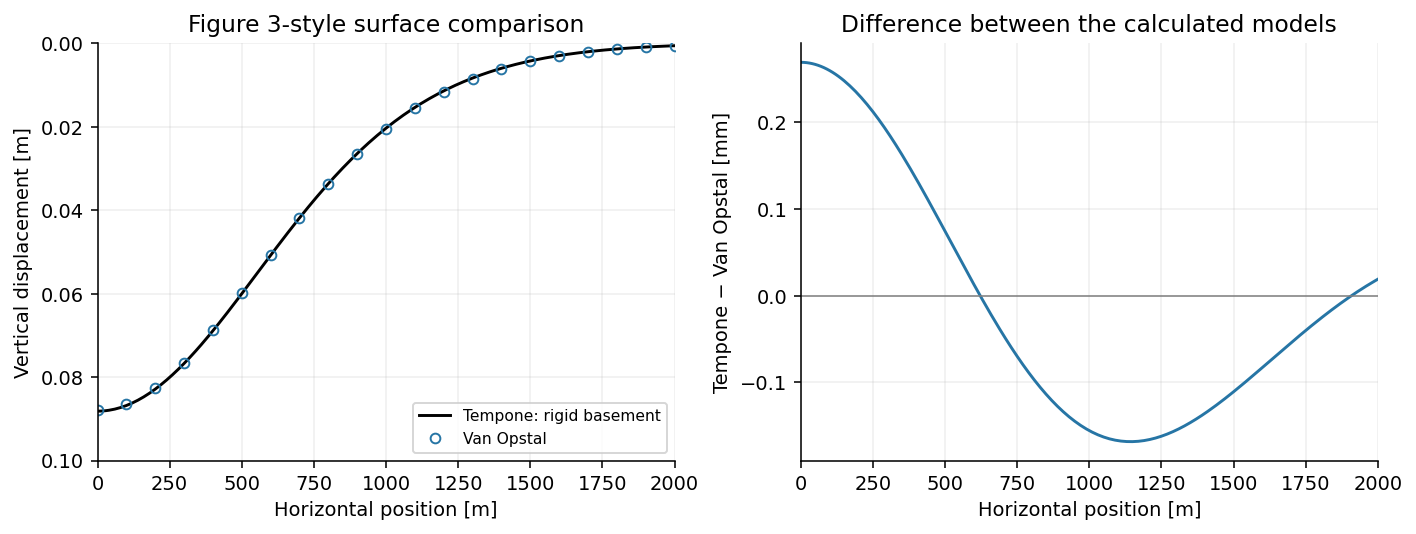

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.7), layout='constrained')
ax[0].plot(x, s_t, color='black', label='Tempone: rigid basement')
ax[0].plot(x[::10], s_vo[::10], 'o', mfc='none', mec='#2675a5', ms=5,
           label='Van Opstal')
ax[0].set(xlabel='Horizontal position [m]', ylabel='Vertical displacement [m]',
          xlim=(0, 2000), ylim=(0.10, 0), title='Figure 3-style surface comparison')
ax[0].legend(fontsize=8, loc='lower right')
ax[1].plot(x, 1000*(s_t-s_vo), color='#2675a5')
ax[1].axhline(0, color='gray', lw=0.8)
ax[1].set(xlabel='Horizontal position [m]', ylabel='Tempone − Van Opstal [mm]',
          xlim=(0, 2000), title='Difference between the calculated models')
plt.show()


**Interpretation.** The independently evaluated kernels give nearly overlapping surface
profiles for this setup. Their small difference is retained, without tuning either curve.
The supplied screenshot of the published Figure 3 appears to have centre displacement
around **0.095 m**, while the stated setup here gives about **0.088 m**. Consequently this
is a reproduction of the comparison and stated parameters, **not an exact numerical
reproduction of the published plot**. The original cell coordinates/calculation are needed
to resolve that discrepancy; its cause has not been established. Neither model is rescaled
to the image. No published numerical points are claimed or inferred from the markers above.


## 4. Apply the same mathematics to a given reservoir table

This optional section reads the repository's unchanged synthetic dataset. Its $C_m$ and
depletion columns use **1/bar and bar**. It retains the dataset's per-reservoir basement
factors: summing these different-basement kernels is an illustrative approximation, not
a solution for one common horizontal basement. For a common basement, replace `k_m`
with a single prescribed depth. The first three sections are self-contained.


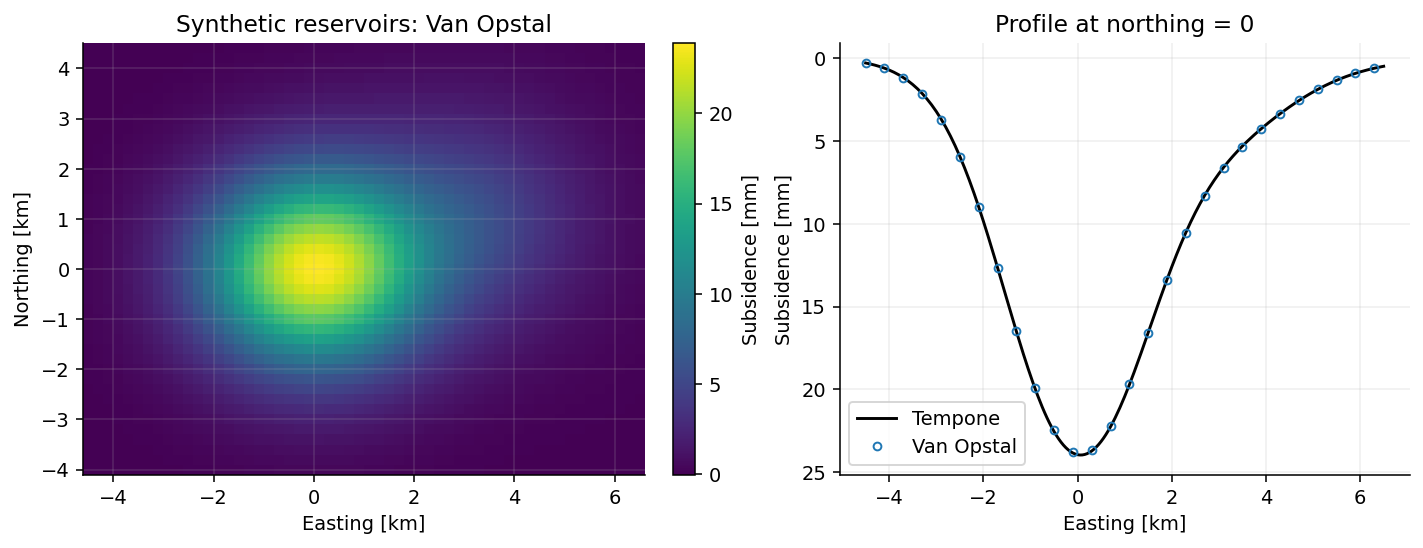

In [6]:
data = pd.read_csv('data/synthetic_reservoir.csv')
data['c_m'] = data.reservoir_depth_m
data['k_m'] = data.c_m*data.basement_depth_factor
data['D_m3'] = (data.source_cell_area_m2*data.thickness_m
                *data.compaction_coefficient_per_bar*data.pressure_depletion_bar)
gx, gy = np.arange(-4500, 6501, 200), np.arange(-4000, 4501, 200)
xx, yy = np.meshgrid(gx, gy)
surface = subsidence(xx, yy, data, van_opstal)
profile_x = np.linspace(-4500, 6500, 221)
profile_vo = subsidence(profile_x, 0.0, data, van_opstal)
profile_t = subsidence(profile_x, 0.0, data, tempone)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), layout='constrained')
m = ax[0].pcolormesh(xx/1000, yy/1000, surface*1000, shading='auto', cmap='viridis')
fig.colorbar(m, ax=ax[0], label='Subsidence [mm]')
ax[0].set(xlabel='Easting [km]', ylabel='Northing [km]',
          title='Synthetic reservoirs: Van Opstal', aspect='equal')
ax[1].plot(profile_x/1000, profile_t*1000, color='black', label='Tempone')
ax[1].plot(profile_x[::8]/1000, profile_vo[::8]*1000, 'o', mfc='none', ms=4,
           label='Van Opstal')
ax[1].set(xlabel='Easting [km]', ylabel='Subsidence [mm]', title='Profile at northing = 0')
ax[1].invert_yaxis()
ax[1].legend()
plt.show()


## References

- Tempone, P., Fjær, E. & Landrø, M. (2010). *Improved solution of displacements due to
  a compacting reservoir over a rigid basement*. Applied Mathematical Modelling 34,
  3352–3362. [doi:10.1016/j.apm.2010.02.025](https://doi.org/10.1016/j.apm.2010.02.025).
  Surface specialization: Eqs. (26), (29)–(34); example: Section 5 and Figure 3.
- Van Opstal, G.H.C. (1974). *The effect of base-rock rigidity on subsidence due to
  reservoir compaction*. Proceedings of the Third Congress of the ISRM, 1102–1111.
- Geertsma, J. (1973). *A basic theory of subsidence due to reservoir compaction:
  the homogeneous case*. Verhandelingen KNGMG 28, 43–62.

Van Opstal implementation and synthetic data adapted from this repository at
[`ec202514`](https://github.com/asengel/subsidence-model/tree/ec202514c3f76f62e044069ef16c5aa90ed099b6).
